# Лабораторная работа №3: Линейные модели. Кросс-валидация.

**Студент:** Гайфуллина Рената, ПМИ 3-1

## Упражнение 2. Вариант 1

В практическом примере ниже показано:

* как пользоваться инструментами предварительного анализа для поиска линейных взаимосвязей
* как строить и интерпретировать линейные модели с логарифмами
* как оценивать точность моделей с перекрёстной проверкой (LOOCV)

*Модели*: множественная линейная регрессия
*Данные*: `Boston_for_lab` (источник: <https://github.com/ania607/ML/tree/main/data>)

**Вариант 1.**
* Зависимая переменная: `medv` — медианная стоимость домов, тыс. долл. США.
* Объясняющие непрерывные: `zn` — доля земли под жилую застройку; `indus` — доля акров, не связанных с розничной торговлей, на город.
* Объясняющая фиктивная: `tax_over_400` — 1, если полная ставка налога на имущество на $10000 превышает 400.
* Проверка точности: **LOOCV**.

# Указания к выполнению


## Загружаем пакеты

In [1]:
# загрузка пакетов: инструменты --------------------------------------------
#  работа с массивами
import numpy as np
#  фреймы данных
import pandas as pd
#  графики
import matplotlib as mpl
#  стили и шаблоны графиков на основе matplotlib
import seaborn as sns
# перекодировка категориальных переменных
from sklearn.preprocessing import LabelEncoder
#  тест Шапиро-Уилка на нормальность распределения
from scipy.stats import shapiro
#  для таймера
import time

# загрузка пакетов: модели -------------------------------------------------
#  линейные модели
import sklearn.linear_model as skl_lm
#  расчёт MSE
from sklearn.metrics import mean_squared_error
#  кросс-валидация
from sklearn.model_selection import train_test_split, LeaveOneOut 
from sklearn.model_selection import KFold, cross_val_score
#  полиномиальные модели
from sklearn.preprocessing import PolynomialFeatures

In [3]:
# константы
#  ядро для генератора случайных чисел
my_seed = 1
#  создаём псевдоним для короткого обращения к графикам
plt = mpl.pyplot
# настройка стиля и отображения графиков
#  примеры стилей и шаблонов графиков: 
#  http://tonysyu.github.io/raw_content/matplotlib-style-gallery/gallery.html
mpl.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")
# раскомментируйте следующую строку, чтобы посмотреть палитру
# sns.color_palette("Set2")

## Загружаем данные

Набор данных `Boston_for_lab` в формате .csv доступен для загрузки по адресу:
<https://raw.githubusercontent.com/ania607/ML/main/data/Boston_for_lab.csv>.
Загружаем данные во фрейм и оставляем только переменные своего варианта.

In [4]:
# читаем таблицу из файла .csv во фрейм
fileURL = 'https://raw.githubusercontent.com/ania607/ML/main/data/Boston_for_lab.csv'
DF_raw = pd.read_csv(fileURL)

# выясняем размерность фрейма
print('Число строк и столбцов в наборе данных:\n', DF_raw.shape)

Число строк и столбцов в наборе данных:
 (506, 15)


In [5]:
# первые 5 строк фрейма
DF_raw.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv,tax_over_400
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0,0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6,0
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7,0
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4,0
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2,0


Здесь:
* **crim** — уровень преступности на душу населения по району;
* **zn** — доля земли под жилую застройку;
* **indus** — доля акров, не связанных с розничной торговлей, на город;
* **chas** — фиктивная переменная реки Чарльз;
* **nox** — концентрация оксидов азота;
* **rm** — среднее количество комнат в доме;
* **age** — доля домов, построенных до 1940 г.;
* **dis** — средневзвешенное расстояние до пяти бостонских центров занятости;
* **rad** — индекс доступности радиальных шоссе;
* **tax** — полная ставка налога на имущество на $10000;
* **ptratio** — соотношение числа учеников и учителей в городе;
* **black** — доля «чёрного» населения;
* **lstat** — % населения с низким статусом;
* **medv** — медианная стоимость домов, тыс. долл. США;
* **tax_over_400** — 1, если полная ставка налога на имущество на $10000 превышает 400.

In [6]:
# типы столбцов фрейма
DF_raw.dtypes

crim            float64
zn              float64
indus           float64
chas              int64
nox             float64
rm              float64
age             float64
dis             float64
rad               int64
tax               int64
ptratio         float64
black           float64
lstat           float64
medv            float64
tax_over_400      int64
dtype: object

Проверим, нет ли в таблице пропусков.  

In [7]:
# считаем пропуски в каждом столбце
DF_raw.isnull().sum()

crim            0
zn              0
indus           0
chas            0
nox             0
rm              0
age             0
dis             0
rad             0
tax             0
ptratio         0
black           0
lstat           0
medv            0
tax_over_400    0
dtype: int64

Пропусков не обнаружено. Оставляем в наборе данных только переменные варианта 1: `medv`, `zn`, `indus`, `tax_over_400`.

In [8]:
# оставляем в наборе данных только то, что нужно
DF_all = DF_raw[['medv', 'zn', 'indus', 'tax_over_400']].copy()

DF_all.columns

Index(['medv', 'zn', 'indus', 'tax_over_400'], dtype='str')

In [9]:
DF_all.dtypes

medv            float64
zn              float64
indus           float64
tax_over_400      int64
dtype: object

Прежде чем переходить к анализу данных, разделим фрейм на две части: одна (80%) станет основой для обучения моделей, на вторую (20%) мы сделаем прогноз по лучшей модели.

In [10]:
# данные для построения моделей
DF, DF_predict = train_test_split(
    DF_all,
    test_size=0.2,
    random_state=my_seed,
    shuffle=True
)

# сбрасываем индексы
DF = DF.reset_index(drop=True)
DF_predict = DF_predict.reset_index(drop=True)

print('Размер обучающей выборки:', DF.shape)
print('Размер отложенной выборки:', DF_predict.shape)

Размер обучающей выборки: (404, 4)
Размер отложенной выборки: (102, 4)


## Предварительный анализ данных

### Считаем описательные статистики

Рассчитаем описательные статистики для непрерывных переменных.

In [59]:
# описательные статистики для непрерывных переменных
DF[['medv', 'zn', 'indus', 'tax_over_400']].describe()

,medv,zn,indus,tax_over_400
count,404.000000,404.000000,404.000000,404.000000
mean,22.522277,11.527228,11.077500,0.381188
std,8.998991,23.288284,6.848412,0.486281
min,5.000000,0.000000,0.460000,0.000000
25%,17.175000,0.000000,5.190000,0.000000
50%,21.050000,0.000000,9.125000,0.000000
75%,25.225000,20.000000,18.100000,1.000000
max,50.000000,100.000000,27.740000,1.000000


**Основные выводы:**
* **medv:** Средняя стоимость (22.52) выше медианы (21.05) — есть правосторонняя асимметрия (дорогие дома).
* **zn:** Сильно скошена вправо. Медиана равна 0 (в большинстве районов жилой застройки нет). Требует внимания при анализе.
* **indus:** Распределена относительно равномерно (среднее 11.08, медиана 9.13).
* **tax_over_400:** Среднее 0.38 — примерно в 38% районов налог превышает 400.

### Строим графики  

Посмотрим на графики взаимного разброса непрерывных переменных. 

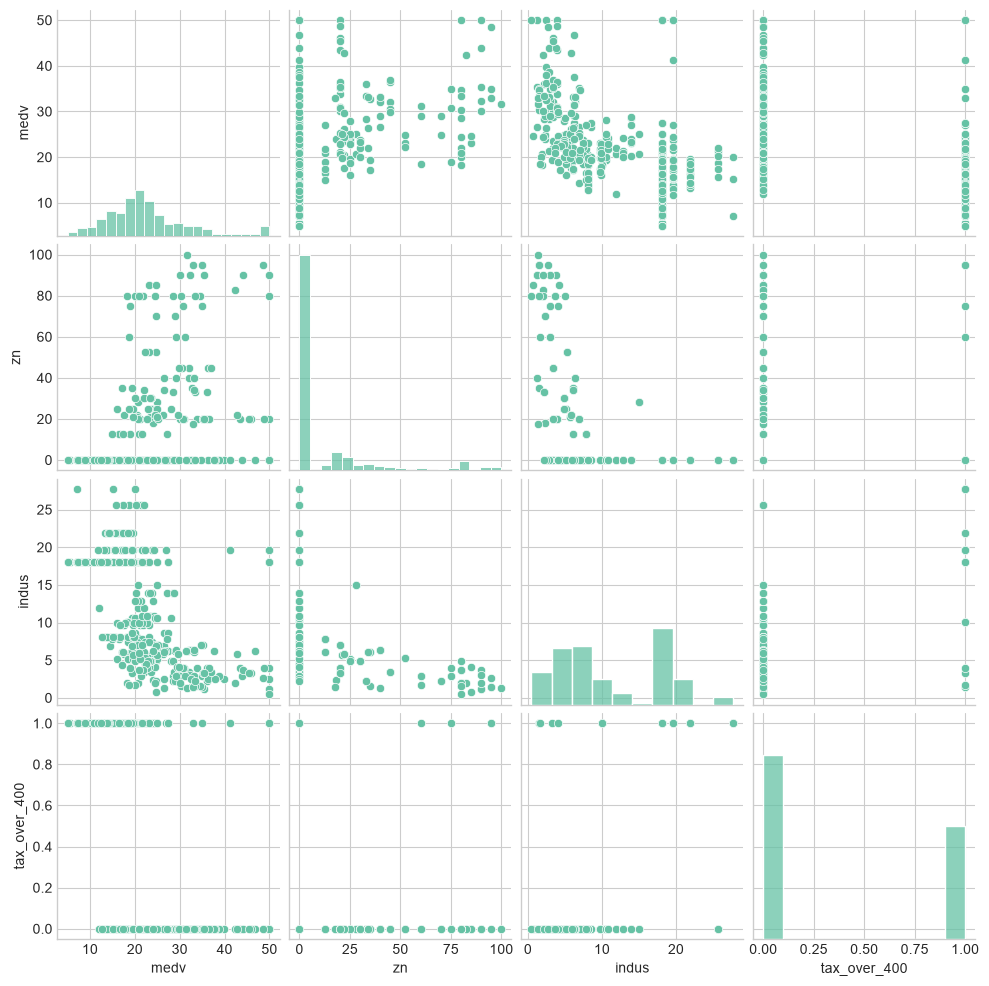

In [60]:
# матричный график разброса с линиями регрессии
sns.pairplot(DF[['medv', 'zn', 'indus', 'tax_over_400']])
plt.show()

**Графики рассеяния:**
* **medv ~ indus:** Заметная **отрицательная** нелинейная связь (чем больше промышленных зон, тем дешевле жилье).
* **medv ~ zn:** Слабая положительная связь, но заметно выделяется вертикальная полоса нулей `zn`, где цены сильно разнятся.
* **medv ~ tax_over_400:** В районах с налогом > 400 стоимость домов в среднем ниже.
* **zn ~ indus:** Обратная связь (там, где жилая застройка, меньше промышленности).

Построим график, раскрасив точки цветом в зависимости от фиктивной переменной `tax_over_400`.

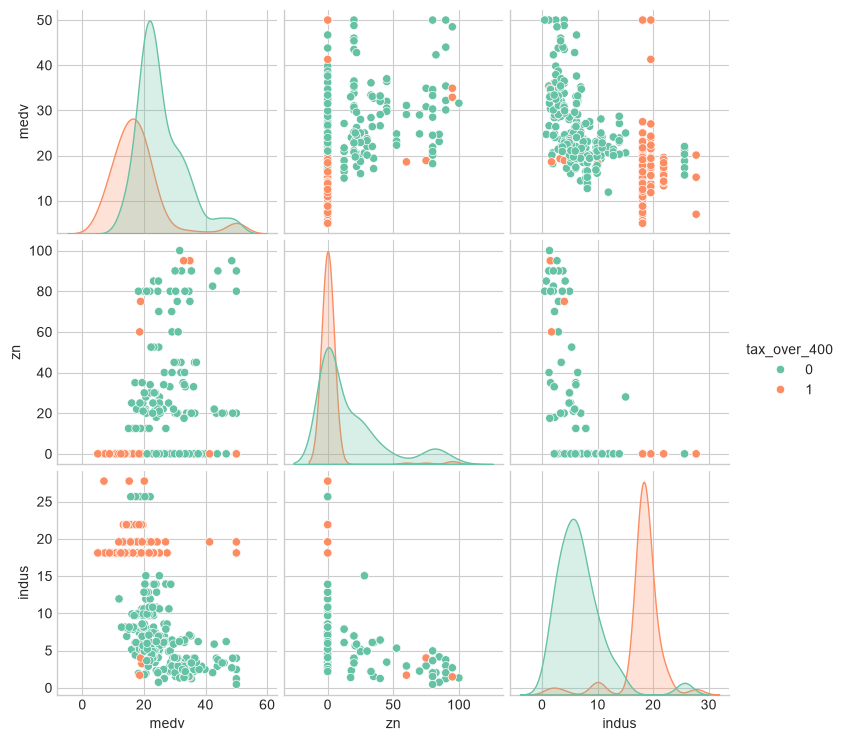

In [13]:
# матричный график разброса с цветом по tax_over_400
sns.pairplot(DF[['medv', 'zn', 'indus', 'tax_over_400']],
             hue='tax_over_400')
plt.show()

Посмотрим на корреляционные матрицы непрерывных переменных фрейма — по всем наблюдениям и отдельно по двум значениям `tax_over_400`.

In [62]:
# корреляционная матрица по всем наблюдениям
corr_mat = DF[['medv', 'zn', 'indus']].corr()
corr_mat.style.background_gradient(cmap='coolwarm').format(precision=2)
#corr_mat

,medv,zn,indus
medv,1.00,0.39,-0.50
zn,0.39,1.00,-0.54
indus,-0.50,-0.54,1.00


Посчитаем корреляционную матрицы для  tax_over_400 == 1

In [20]:
corr_mat = DF.loc[DF['tax_over_400'] == 1, ['medv', 'zn', 'indus']].corr()
corr_mat

,medv,zn,indus
medv,1.000000,0.175033,-0.130872
zn,0.175033,1.000000,-0.673181
indus,-0.130872,-0.673181,1.000000


Посчитаем корреляционную матрицы для  tax_over_400 == 0

In [21]:
# корреляционная матрица по классу tax_over_400 == 0
corr_mat = DF.loc[DF['tax_over_400'] == 0, ['medv', 'zn', 'indus']].corr()
corr_mat

,medv,zn,indus
medv,1.000000,0.370635,-0.428608
zn,0.370635,1.000000,-0.464278
indus,-0.428608,-0.464278,1.000000




### Логарифмируем зависимую переменную  

Важным допущением линейной регрессии является нормальность зависимой переменной. Чтобы добиться нормального распределения, используют логарифмирование. Проверим `medv` на нормальность и, если нужно, прологарифмируем.

In [22]:
# логарифмируем зависимую переменную
DF['log_medv'] = np.log(DF['medv'])

# описательные статистики для непрерывных показателей
DF[['medv', 'log_medv', 'zn', 'indus']].describe()

,medv,log_medv,zn,indus
count,404.000000,404.000000,404.000000,404.000000
mean,22.522277,3.036290,11.527228,11.077500
std,8.998991,0.404748,23.288284,6.848412
min,5.000000,1.609438,0.000000,0.460000
25%,17.175000,2.843452,0.000000,5.190000
50%,21.050000,3.046898,0.000000,9.125000
75%,25.225000,3.227834,20.000000,18.100000
max,50.000000,3.912023,100.000000,27.740000


**Ключевые изменения:**
* **log_medv:** Масштаб переменной значительно сократился (от 1.6 до 3.9). Среднее (3.04) и медиана (3.05) практически совпали, что указывает на устранение сильной правосторонней асимметрии.
* **Предикторы (zn, indus):** Остались без изменений — логарифмирование зависимой переменной на них не влияет.

Проведём формальные тесты на нормальность.

In [23]:
# тестируем на нормальность
for col in ['medv', 'log_medv']:
    stat, p = shapiro(DF[col])
    print(col, 'Statistics=%.2f, p=%.4f' % (stat, p))
    # интерпретация
    alpha = 0.05
    if p > alpha:
        print('Распределение нормально (H0 не отклоняется)\n')
    else:
        print('Распределение не нормально (H0 отклоняется)\n')

medv Statistics=0.93, p=0.0000
Распределение не нормально (H0 отклоняется)

log_medv Statistics=0.97, p=0.0000
Распределение не нормально (H0 отклоняется)



Логарифмирование меняет взаимосвязи между переменными. Посмотрим на графики и корреляционные матрицы снова.

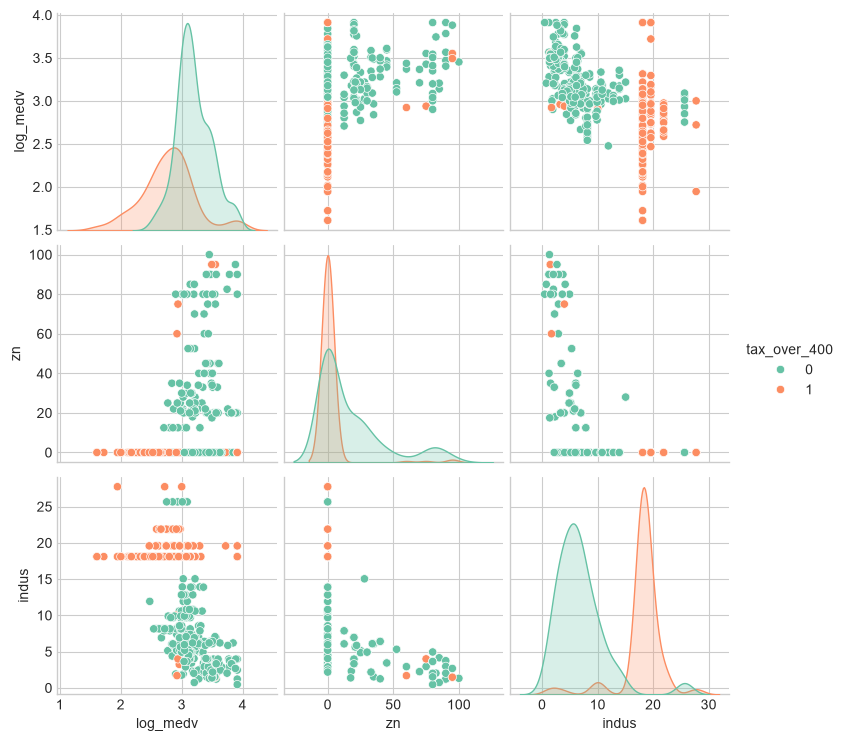

In [24]:
# матричный график разброса с цветом по tax_over_400 (логарифм Y)
sns.pairplot(DF[['log_medv', 'zn', 'indus', 'tax_over_400']],
             hue='tax_over_400')
plt.show()

In [25]:
# корреляционная матрица по классу tax_over_400 == 0 (логарифм Y)
corr_mat = DF.loc[DF['tax_over_400'] == 0,
                  ['log_medv', 'zn', 'indus']].corr()
corr_mat

,log_medv,zn,indus
log_medv,1.000000,0.374459,-0.431701
zn,0.374459,1.000000,-0.464278
indus,-0.431701,-0.464278,1.000000


Для районов с налогом $\le$ 400 (`tax_over_400 == 0`):**
* **`zn` и `log_medv`:** Умеренная положительная связь (**0.37**). Доля жилой застройки заметно повышает стоимость жилья.
* **`indus` и `log_medv`:** Умеренная отрицательная связь (**-0.43**). Промышленные зоны сильно снижают цены.
* **`zn` и `indus`:** Обратная связь (**-0.46**).

In [26]:
# корреляционная матрица по классу tax_over_400 == 1 (логарифм Y)
corr_mat = DF.loc[DF['tax_over_400'] == 1,
                  ['log_medv', 'zn', 'indus']].corr()
corr_mat

,log_medv,zn,indus
log_medv,1.000000,0.181457,-0.158206
zn,0.181457,1.000000,-0.673181
indus,-0.158206,-0.673181,1.000000


Для районов с налогом > 400 (`tax_over_400 == 1`):**
* **`zn` и `log_medv`:** Связь ослабевает почти вдвое (**0.18**). В дорогих районах наличие жилой застройки уже не так сильно влияет на цену.
* **`indus` и `log_medv`:** Отрицательная связь также ослабевает (**-0.16**).
* **`zn` и `indus`:** Обратная связь усиливается (**-0.67**), что говорит о более жестком зонировании (либо жилье, либо заводы).

## Строим модели регрессии

### Спецификация моделей

По итогам предварительного анализа данных можно предложить следующие спецификации линейных регрессионных моделей:

1. `fit_lm_0`: $\hat{medv} = \hat{\beta_0} + \hat{\beta_1} \cdot zn + \hat{\beta_2} \cdot indus + \hat{\beta_3} \cdot tax\_over\_400$  (все переменные)
1. `fit_lm_1`: $\hat{medv} = \hat{\beta_0} + \hat{\beta_1} \cdot tax\_over\_400 + \hat{\beta_2} \cdot zn$
1. `fit_lm_2`: $\hat{medv} = \hat{\beta_0} + \hat{\beta_1} \cdot tax\_over\_400 + \hat{\beta_2} \cdot indus$
1. `fit_lm_3`: $\hat{medv} = \hat{\beta_0} + \hat{\beta_1} \cdot tax\_over\_400 + \hat{\beta_2} \cdot zn \cdot tax\_over\_400 + \hat{\beta_3} \cdot indus$
1. `fit_lm_4`: $\hat{medv} = \hat{\beta_0} + \hat{\beta_1} \cdot tax\_over\_400 + \hat{\beta_2} \cdot indus \cdot tax\_over\_400 + \hat{\beta_3} \cdot zn$

1. `fit_lm_0_log` … `fit_lm_4_log`: то же самое, но для зависимой $\hat{log\_medv}$.

In [27]:
# данные для моделей 1, 6 (базовая: tax_over_400 + zn)
df1 = DF[['medv', 'tax_over_400', 'zn']].copy()

# данные для моделей 2, 7 (tax_over_400 + indus)
df2 = DF[['medv', 'tax_over_400', 'indus']].copy()

# данные для моделей 3, 8 (взаимодействие zn * tax_over_400 + indus)
df3 = DF[['medv', 'tax_over_400', 'zn', 'indus']].copy()
df3.loc[:, 'zn_tax'] = df3.loc[:, 'zn'] * df3.loc[:, 'tax_over_400']
df3 = df3.drop(['zn'], axis=1)

# данные для моделей 4, 9 (взаимодействие indus * tax_over_400 + zn)
df4 = DF[['medv', 'tax_over_400', 'zn', 'indus']].copy()
df4.loc[:, 'indus_tax'] = df4.loc[:, 'indus'] * df4.loc[:, 'tax_over_400']
df4 = df4.drop(['indus'], axis=1)

# данные для моделей 0, 5 (все переменные)
df0 = DF[['medv', 'zn', 'indus', 'tax_over_400']].copy()

In [28]:
# проверка результатов
df4.head()

,medv,tax_over_400,zn,indus_tax
0,25.3,0,0.0,0.0
1,23.3,0,25.0,0.0
2,7.2,1,0.0,18.1
3,21.2,0,0.0,0.0
4,11.7,1,0.0,18.1


Построим модели от всех объясняющих переменных на всех наблюдениях `DF`, чтобы проинтерпретировать параметры.

В модели для зависимой переменной `medv` интерпретация стандартная:
1. Константа – базовый уровень зависимой переменной, когда все объясняющие равны 0.
2. Коэффициент при объясняющей переменной X показывает, на сколько своих единиц измерения изменится Y, если X увеличится на одну свою единицу измерения.

In [29]:
lm = skl_lm.LinearRegression()

# модель со всеми объясняющими, y
X = df0.drop(['medv'], axis=1)
y = df0.medv.values.reshape(-1, 1)
fit_lm_0 = lm.fit(X, y)
print('модель fit_lm_0:\n',
      'константа ', np.around(fit_lm_0.intercept_, 3),
      '\n объясняющие ', list(X.columns.values),
      '\n коэффициенты ', np.around(fit_lm_0.coef_, 3))

модель fit_lm_0:
 константа  [27.097] 
 объясняющие  ['zn', 'indus', 'tax_over_400'] 
 коэффициенты  [[ 0.07  -0.423 -1.823]]


In [30]:
# оценим MSE на обучающей
#  прогнозы
y_pred = fit_lm_0.predict(X)
MSE = sum((y - y_pred.reshape(-1, 1))**2) / len(y)
np.sqrt(MSE)

array([7.67230687])

С интерпретацией модели на логарифме Y дела обстоят сложнее:
1. Константу сначала надо экспоненциировать, далее интерпретировать как для обычной модели регрессии.
2. Коэффициент при X нужно экспоненциировать, затем вычесть из получившегося числа 1, затем умножить на 100. Результат показывает, на сколько процентов изменится (увеличится, если коэффициент положительный, и уменьшится, если отрицательный) зависимая переменная, если X увеличится на одну свою единицу измерения.

In [31]:
# модель со всеми объясняющими, y_log
X = df0.drop(['medv'], axis=1)
y = np.log(df0.medv).values.reshape(-1, 1)
fit_lm_0_log = lm.fit(X, y)
print('модель fit_lm_0_log:\n',
      'константа ', np.around(fit_lm_0_log.intercept_, 3),
      '\n объясняющие ', list(X.columns.values),
      '\n коэффициенты ', np.around(fit_lm_0_log.coef_, 3))

модель fit_lm_0_log:
 константа  [3.269] 
 объясняющие  ['zn', 'indus', 'tax_over_400'] 
 коэффициенты  [[ 0.003 -0.018 -0.179]]


In [32]:
# пересчёт коэффициентов для их интерпретации
np.around((np.exp(fit_lm_0_log.coef_) - 1) * 100, 1)

array([[  0.3,  -1.7, -16.4]])

In [33]:
# оценим MSE на обучающей
#  прогнозы
y_pred = fit_lm_0_log.predict(X)
MSE_log = sum((np.exp(y) - np.exp(y_pred).reshape(-1, 1))**2) / len(y)
np.sqrt(MSE_log)

array([7.73435574])

In [34]:
print('MSE_train модели для medv меньше MSE_train',
      'модели для log(medv) в ', np.around(MSE_log / MSE, 1), 'раз')

MSE_train модели для medv меньше MSE_train модели для log(medv) в  [1.] раз


### Оценка точности

#### LOOCV  

Сделаем перекрёстную проверку точности моделей по одному наблюдению.  

In [35]:
# LeaveOneOut CV
loo = LeaveOneOut()

# модели для y
scores = list()
dfs_y = [df0, df1, df2, df3, df4]

# таймер
tic = time.perf_counter()
for df in dfs_y:
    loo.get_n_splits(df)
    X = df.drop(['medv'], axis=1)
    y = df.medv.values.reshape(-1, 1)
    score = cross_val_score(lm, X, y, cv=loo,
                            scoring='neg_mean_squared_error').mean()
    scores.append(score)

# таймер
toc = time.perf_counter()
print(f"Расчёты методом LOOCV заняли {toc - tic:0.2f} секунд")

Расчёты методом LOOCV заняли 6.74 секунд


In [36]:
df0.shape

(404, 4)

In [37]:
# модели для y_log
scores_log = list()
dfs_y_log = [df0, df1, df2, df3, df4]

# таймер
tic = time.perf_counter()
for df in dfs_y_log:
    loo.get_n_splits(df)
    X = df.drop(['medv'], axis=1)
    y = np.log(df.medv).values.reshape(-1, 1)
    score = cross_val_score(lm, X, y, cv=loo, n_jobs=1,
                            scoring='neg_mean_squared_error').mean()
    scores_log.append(score)

# таймер
toc = time.perf_counter()
print(f"Расчёты методом LOOCV заняли {toc - tic:0.2f} секунд")

Расчёты методом LOOCV заняли 6.50 секунд


Сравним ошибки для моделей на исходных значениях `medv` с ошибками моделей на логарифме.

In [38]:
scores

[np.float64(-59.98670778711935),
 np.float64(-62.2517489663313),
 np.float64(-61.54055751817004),
 np.float64(-61.901976489492576),
 np.float64(-62.404452952737834)]

In [39]:
[np.around(-x, 2) for x in scores]

[np.float64(59.99),
 np.float64(62.25),
 np.float64(61.54),
 np.float64(61.9),
 np.float64(62.4)]

In [40]:
[np.around(-x, 3) for x in scores_log]

[np.float64(0.112),
 np.float64(0.116),
 np.float64(0.114),
 np.float64(0.114),
 np.float64(0.116)]

Определим самые точные модели отдельно на `medv` и на `log_medv`.

In [46]:
# самая точная на medv
fits = ['fit_lm_0', 'fit_lm_1', 'fit_lm_2', 'fit_lm_3', 'fit_lm_4']
print('Наименьшая ошибка на тестовой с LOOCV у модели',
      fits[scores.index(max(scores))],
      ':\nMSE_loocv =', np.around(-max(scores), 0))

Наименьшая ошибка на тестовой с LOOCV у модели fit_lm_0 :
MSE_loocv = 60.0


In [47]:
# самая точная на log(medv)
fits = ['fit_lm_0_log', 'fit_lm_1_log', 'fit_lm_2_log',
        'fit_lm_3_log', 'fit_lm_4_log']
print('Наименьшая ошибка на тестовой с LOOCV у модели',
      fits[scores_log.index(max(scores_log))],
      ':\nMSE_loocv =', np.around(-max(scores_log), 3))

Наименьшая ошибка на тестовой с LOOCV у модели fit_lm_0_log :
MSE_loocv = 0.112


#### Прогноз на отложенные наблюдения

Самой точной среди моделей для `medv` оказалась `fit_lm_0`, а среди моделей для `log_medv` – `fit_lm_0_log`. Оценим точность прогноза по этим моделям на отложенные наблюдения и посчитаем MSE_test вручную.

In [64]:
# прогноз по лучшей модели на medv (fit_lm_0)
#  модель на всех обучающих наблюдениях
X = df0.drop(['medv'], axis=1)
y = df0.medv.values.reshape(-1, 1)
fit_lm_0 = lm.fit(X, y)

#  значения y на отложенных наблюдениях
y = DF_predict[['medv']].values.reshape(-1, 1)

#  матрица объясняющих на отложенных наблюдениях
X = DF_predict[['zn', 'indus', 'tax_over_400']].copy()

#  прогнозы
y_pred = fit_lm_0.predict(X)

# ошибка (вручную)
MSE = np.sum((y - y_pred.reshape(-1, 1))**2) / len(y)
print('MSE модели fit_lm_0 на отложенных наблюдениях = %.2f' % MSE)

MSE модели fit_lm_0 на отложенных наблюдениях = 79.81


In [65]:
# прогноз по лучшей модели на log(medv) (fit_lm_0_log)
# модель
X = df0.drop(['medv'], axis=1)
y = np.log(df0['medv']).values.reshape(-1, 1)
fit_lm_0_log = lm.fit(X, y)

#  значения y на отложенных наблюдениях
y = np.log(DF_predict[['medv']].values.reshape(-1, 1))

#  матрица объясняющих на отложенных наблюдениях
X = DF_predict[['zn', 'indus', 'tax_over_400']].copy()

#  прогнозы
y_pred = fit_lm_0_log.predict(X)

# ошибка (вручную) — np.sum, чтобы получить скаляр (см. прошлый ответ)
MSE_log = np.sum((np.exp(y) - np.exp(y_pred).reshape(-1, 1))**2) / len(y)
print('MSE модели fit_lm_0_log на отложенных наблюдениях = %.2f' % MSE_log)

MSE модели fit_lm_0_log на отложенных наблюдениях = 81.59


In [66]:
np.sqrt(MSE_log) / np.mean(DF_predict[['medv']]) * 100

np.float64(40.011755281250885)

In [67]:
np.sqrt(MSE) / np.mean(DF_predict[['medv']]) * 100

np.float64(39.57374520044101)

### Вывод

По результатам LOOCV и проверки на отложенной выборке лучшей оказалась модель `fit_lm_0`:

$$\hat{medv} = \hat{\beta_0} + \hat{\beta_1} \cdot tax\_over\_400 + \hat{\beta_2} \cdot zn \cdot tax\_over\_400 + \hat{\beta_3} \cdot indus$$

Выведем её коэффициенты и проинтерпретируем их.

In [69]:
X = df0.drop(['medv'], axis=1)
y = df0.medv.values.reshape(-1, 1)
fit_lm_0 = lm.fit(X, y)

print('модель fit_lm_0:\n',
      'константа ', np.around(fit_lm_0.intercept_, 3),
      '\n объясняющие ', list(df0.drop(['medv'], axis=1).columns.values),
      '\n коэффициенты ', np.around(fit_lm_0.coef_, 3))

модель fit_lm_0:
 константа  [27.097] 
 объясняющие  ['zn', 'indus', 'tax_over_400'] 
 коэффициенты  [[ 0.07  -0.423 -1.823]]


### Вывод

По результатам LOOCV и проверки на отложенной выборке лучшей оказалась модель `fit_lm_0`:

$$\hat{medv} = \hat{\beta_0} + \hat{\beta_1} \cdot zn + \hat{\beta_2} \cdot indus + \hat{\beta_3} \cdot tax\_over\_400$$

**Интерпретация:**
* **Константа** (27.097) — базовый уровень `medv` при нулевых значениях всех предикторов.
* **Коэффициент при `zn`** (0.07) — при увеличении доли жилой застройки на 1 п.п. медианная стоимость дома растет на 0.07 тыс. долл.
* **Коэффициент при `indus`** (-0.423) — при увеличении доли промышленных земель на 1 п.п. стоимость дома снижается на 0.423 тыс. долл.
* **Коэффициент при `tax_over_400`** (-1.823) — в районах с налогом > 400 стоимость домов в среднем на 1.823 тыс. долл. ниже при прочих равных.